## Import Data

In [1]:
import pandas as pd
import numpy as np
import joblib
import os

# Load datasets
X_train = pd.read_csv("../data/processed/X_train.csv")
X_test = pd.read_csv("../data/processed/X_test.csv")

y_train = pd.read_csv("../data/processed/y_train.csv").squeeze()
y_test = pd.read_csv("../data/processed/y_test.csv").squeeze()

# Load previous model comparison
results_df = pd.read_csv(
    "../data/processed/model_comparison.csv"
)

# Load preprocessor configuration
preprocessor = joblib.load("../models/preprocessor.pkl")

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

display(results_df)

Training: (1600, 15)
Testing: (400, 15)


,Model,Mean_F1_Macro,Std_F1_Macro
0,Logistic Regression,0.764353,0.021291
1,SVM,0.732457,0.013543
2,Gradient Boosting,0.705387,0.019583
3,Random Forest,0.699267,0.012802
4,KNN,0.613907,0.018648
5,Decision Tree,0.593064,0.022650


## Select Best 3 Model

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

# Define available models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ),

    "Extra Trees": ExtraTreesClassifier(
        random_state=42,
        n_jobs=1
    ),

    "KNN": KNeighborsClassifier(),

    "SVM": SVC(),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

# Select top 3 models
top_models = results_df.nlargest(
    3,
    "Mean_F1_Macro"
)["Model"].tolist()

print("Selected Models:", top_models)

Selected Models: ['Logistic Regression', 'SVM', 'Gradient Boosting']


## Hyperparameter Optimization — GridSearchCV

In [3]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline

# Hyperparameter grids
param_grids = {

    "Logistic Regression": {
        "classifier__C": [0.01, 0.1, 1, 10, 100],
        "classifier__solver": ["lbfgs"],
        "classifier__class_weight": [None, "balanced"]
    },
    "SVM": {
        "classifier__C": [0.1, 1, 10, 100],
        "classifier__kernel": ["linear", "rbf"],
        "classifier__class_weight": [None, "balanced"]
    },

    "Gradient Boosting": {
        "classifier__n_estimators": [50, 100, 200],
        "classifier__learning_rate": [0.01, 0.1, 0.2],
        "classifier__max_depth": [2, 3, 5]
    }
}

In [4]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

optimized_models = {}
optimization_results = []

for name in top_models:

    print(f"\nOptimizing: {name}")

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", models[name])
    ])

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        scoring="f1_macro",
        cv=cv,
        n_jobs=-1,
        refit=True,
        verbose=1
    )

    grid_search.fit(X_train, y_train)

    optimized_models[name] = grid_search.best_estimator_

    optimization_results.append({
        "Model": name,
        "Best_CV_F1_Macro": grid_search.best_score_,
        "Best_Params": grid_search.best_params_
    })

    print("Best Score:", grid_search.best_score_)
    print("Best Parameters:", grid_search.best_params_)


Optimizing: Logistic Regression
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best Score: 0.7671662785219605
Best Parameters: {'classifier__C': 1, 'classifier__class_weight': 'balanced', 'classifier__solver': 'lbfgs'}

Optimizing: SVM
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best Score: 0.7620919118393005
Best Parameters: {'classifier__C': 10, 'classifier__class_weight': None, 'classifier__kernel': 'linear'}

Optimizing: Gradient Boosting
Fitting 5 folds for each of 27 candidates, totalling 135 fits
Best Score: 0.7179735865260073
Best Parameters: {'classifier__learning_rate': 0.1, 'classifier__max_depth': 2, 'classifier__n_estimators': 200}


## Oprimized Models comparaison

In [5]:
optimization_df = pd.DataFrame(
    optimization_results
)

optimization_df = optimization_df.sort_values(
    by="Best_CV_F1_Macro",
    ascending=False
)

display(optimization_df)

,Model,Best_CV_F1_Macro,Best_Params
0,Logistic Regression,0.767166,"{'classifier__C': 1, 'classifier__class_weight..."
1,SVM,0.762092,"{'classifier__C': 10, 'classifier__class_weigh..."
2,Gradient Boosting,0.717974,"{'classifier__learning_rate': 0.1, 'classifier..."


In [6]:
comparison = results_df[
    ["Model", "Mean_F1_Macro"]
].merge(
    optimization_df[
        ["Model", "Best_CV_F1_Macro"]
    ],
    on="Model",
    how="inner"
)

comparison["Improvement"] = (
    comparison["Best_CV_F1_Macro"]
    - comparison["Mean_F1_Macro"]
)

display(comparison)

,Model,Mean_F1_Macro,Best_CV_F1_Macro,Improvement
0,Logistic Regression,0.764353,0.767166,0.002813
1,SVM,0.732457,0.762092,0.029635
2,Gradient Boosting,0.705387,0.717974,0.012586


## Visualisation the comparison

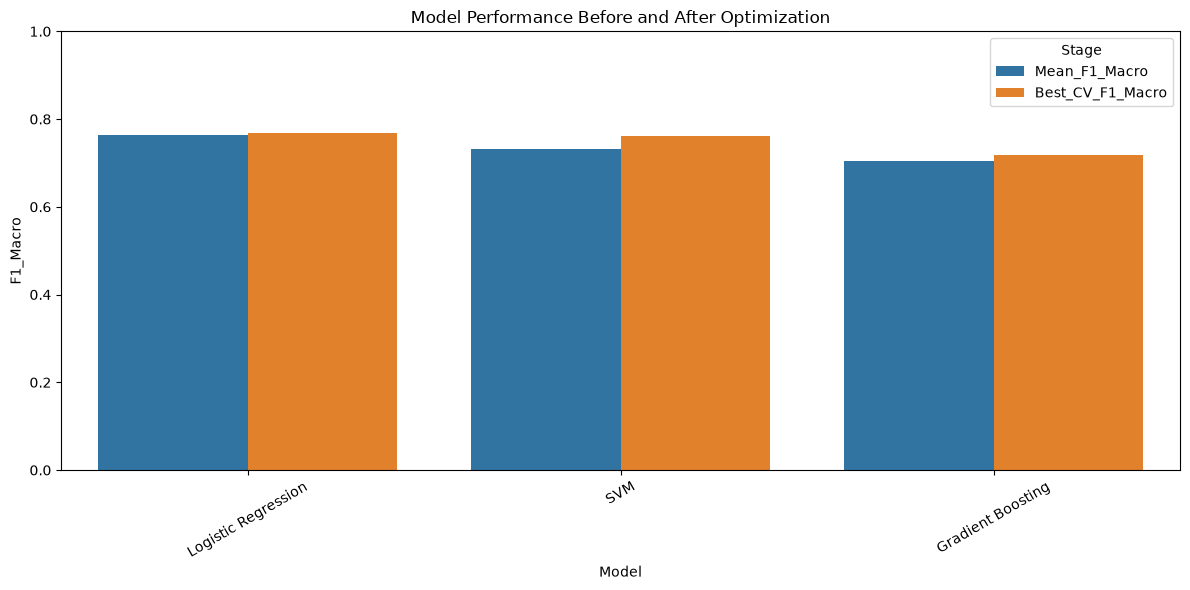

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

comparison_plot = comparison.melt(
    id_vars="Model",
    value_vars=[
        "Mean_F1_Macro",
        "Best_CV_F1_Macro"
    ],
    var_name="Stage",
    value_name="F1_Macro"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=comparison_plot,
    x="Model",
    y="F1_Macro",
    hue="Stage"
)

plt.title("Model Performance Before and After Optimization")
plt.xticks(rotation=30)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

## Select Optimized model 

In [9]:
best_optimized_name = optimization_df.iloc[0]["Model"]

best_pipeline = optimized_models[best_optimized_name]

best_cv_score = optimization_df.iloc[0]["Best_CV_F1_Macro"]

print("Best Optimized Model:", best_optimized_name)
print("Best CV F1-Macro:", best_cv_score)

Best Optimized Model: Logistic Regression
Best CV F1-Macro: 0.7671662785219605


## Test the selected model on test data


In [10]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report
)

# Predict on test data
y_pred = best_pipeline.predict(X_test)

# Calculate metrics
final_results = {
    "Model": best_optimized_name,
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision_Macro": precision_score(
        y_test, y_pred, average="macro"
    ),
    "Recall_Macro": recall_score(
        y_test, y_pred, average="macro"
    ),
    "F1_Macro": f1_score(
        y_test, y_pred, average="macro"
    ),
    "Balanced_Accuracy": balanced_accuracy_score(
        y_test, y_pred
    )
}

final_results_df = pd.DataFrame([final_results])

display(final_results_df)

,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,Balanced_Accuracy
0,Logistic Regression,0.7125,0.719102,0.711481,0.714376,0.711481


## visualize the confusion matrix

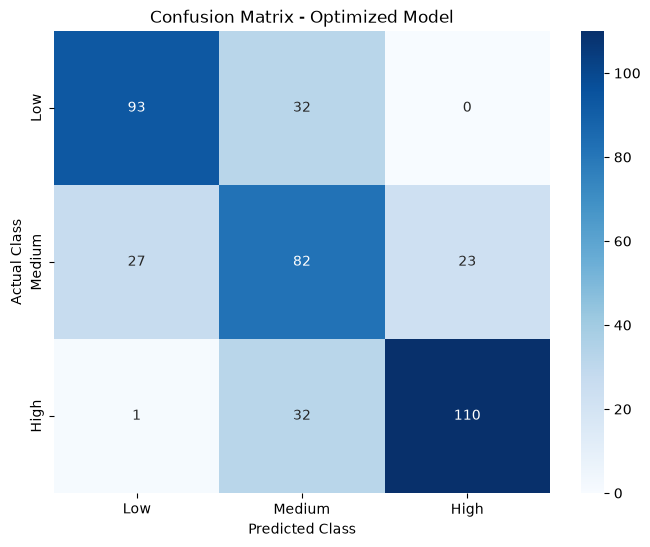

In [11]:
from sklearn.metrics import confusion_matrix

labels = ["Low", "Medium", "High"]

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Confusion Matrix - Optimized Model")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()

## analyse error prediction

In [12]:
errors_df = X_test.copy()

errors_df["Actual"] = y_test.values
errors_df["Predicted"] = y_pred

# Extract incorrect predictions
errors_df = errors_df[
    errors_df["Actual"] != errors_df["Predicted"]
]

print("Total errors:", len(errors_df))

display(errors_df.head(10))

Total errors: 115


,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Actual,Predicted
0,21,Male,3,8.2,20.2,2.28,5.6,6.9,Low,7.2,6.3,86.1,No,Average,No,Low,Medium
2,24,Female,3,5.8,17.1,2.44,6.4,8.8,Moderate,2.5,8.2,83.8,Yes,Average,No,Low,Medium
8,24,Female,1,5.8,27.5,2.27,3.6,5.9,Moderate,6.1,5.6,85.6,No,Average,No,High,Medium
9,22,Male,1,NaN,14.9,2.20,6.4,7.6,Low,3.8,5.5,77.9,Yes,Poor,No,High,Medium
18,21,Female,3,5.8,22.6,2.86,4.8,7.9,Low,6.2,9.5,91.8,No,Poor,Yes,Medium,High
19,18,Male,3,7.1,22.4,2.73,6.8,8.9,Low,6.0,8.4,78.3,No,Poor,Yes,High,Medium
24,19,Female,3,7.2,20.6,2.89,7.0,9.2,Moderate,4.5,2.0,75.0,Yes,Average,No,High,Medium
27,21,Non-binary,4,6.0,25.7,2.90,5.7,9.3,High,3.8,NaN,86.5,No,Average,Yes,Medium,Low
29,20,Female,1,7.0,23.5,2.81,6.2,10.1,Low,4.6,2.9,85.1,No,Poor,No,Medium,High
30,21,Female,4,6.7,24.4,2.76,4.9,4.6,Low,5.8,8.0,91.9,Yes,Average,No,Medium,Low


In [13]:
error_analysis = pd.crosstab(
    errors_df["Actual"],
    errors_df["Predicted"]
)

display(error_analysis)

Predicted,High,Low,Medium
Actual,,,
High,0,1,32
Low,0,0,32
Medium,23,27,0
